# 05 · Agentes con LangGraph

Hasta ahora el pipeline RAG era una línea recta: recuperar, generar. Los asistentes reales se ramifican. Una pregunta
sobre un número debería ir a una base de datos, no a los documentos. Una pregunta fuera de tema debería rechazarse antes
de costar una llamada al modelo. Una respuesta que no pasa una comprobación debería hacer volver al sistema para
intentarlo de nuevo, una vez, con una consulta mejor. Dos recuperadores deberían ejecutarse **a la vez**. Y un
seguimiento como *"¿y quién decide eso?"* solo tiene sentido si el sistema recuerda el turno anterior.

Un **grafo de estados** es la forma limpia de expresarlo. **LangGraph** modela una aplicación como nodos (funciones
normales que leen y actualizan un *estado* compartido) conectados por aristas, algunas de ellas *condicionales*. El
flujo pasa a ser un dato que puedes dibujar, probar, pausar y reanudar, en lugar de `if` enterrados en una función. Un
agente de analítica de parques eólicos de este portafolio es exactamente un grafo así: ingesta, previsión, diagnóstico,
después recuperación de documentos y análisis de imágenes **en paralelo**, investigación, y por último *recomendar* o
*recomendar un reentrenamiento* (una rama condicional), y al final explicar.

Todo aquí es determinista y funciona sin conexión: los pasos "de modelo" son sustitutos locales, de modo que lo que ves
es la maquinaria del grafo, que es lo que se traslada a un modelo real.

**Aprenderás**
1. Estado, nodos y aristas: las tres ideas de LangGraph
2. Enrutado condicional: enviar una pregunta a los documentos, a un esbozo de base de datos o a un rechazo
3. Ramas paralelas: dos recuperadores a la vez, unidos antes del paso siguiente, y cuánto tiempo ahorra eso
4. Un bucle de comprobar y reintentar: verificar la respuesta, reescribir la consulta, probar una vez más y después rendirse con honestidad
5. Puntos de control: memoria de conversación por hilo, para que funcione una pregunta de seguimiento
6. Medir qué aporta el bucle y qué no

## 1. Los ingredientes

Reutilizamos el manual de Harbourview y los recuperadores de los módulos 01 y 02: BM25 (léxico) y embeddings de MiniLM
(semántico). Cada uno será un nodo del grafo.

In [1]:
# El manual de Harbourview: 22 pasajes, ficticios, escritos para este curso
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, pregunta, pasaje correcto, dato que debe contener la respuesta); None = el manual no lo dice
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [2]:
import re, time, math, operator, warnings
from typing import Annotated, TypedDict
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sentence_transformers import SentenceTransformer

ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
section_of = {pid: section for pid, section, _ in PASSAGES}
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
E = minilm.encode(chunks, normalize_embeddings=True)

STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float); self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        self.idf = {t: math.log(1 + (len(docs) - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s
bm25 = BM25(chunks)

PARAPHRASES = [
    ("r01", "Are boats cancelled when the sea is too rough?", "p02"),
    ("r02", "Can I go up the tower alone to fix something?", "p03"),
    ("r03", "How big are the blades?", "p04"),
    ("r04", "Who do I call in the middle of the night about an accident?", "p18"),
    ("r05", "What if the oil in the gearbox gets dirty?", "p07"),
    ("r06", "Do you stop work when whales or seals swim close?", "p13"),
    ("r07", "How much spare equipment is kept on shore?", "p16"),
    ("r08", "Is the farm allowed to produce at full output?", "p21"),
    ("r09", "What should new colleagues do before their first trip?", "p22"),
    ("r10", "How should rubbish and old oil be handled?", "p15"),
]
ANSWERABLE = [(q[0], q[1], q[2]) for q in QUESTIONS if q[2]] + PARAPHRASES     # 24 preguntas con pasaje correcto
UNANSWERABLE = [("u01", q[1], None) for q in QUESTIONS if not q[2]] + [
    ("u03", "What is the best pasta recipe?", None), ("u04", "How do I reset my email password?", None)]
print(len(ANSWERABLE), "answerable and", len(UNANSWERABLE), "unanswerable questions")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3358.39it/s]

24 answerable and 4 unanswerable questions


## 2. Estado, nodos y aristas

El **estado** es un diccionario tipado que todos los nodos pueden leer y actualizar en parte. Un nodo es una función del
estado a un estado *parcial* (solo las claves que cambia). Cuando varios nodos pueden escribir la misma clave, un
**reductor** dice cómo combinarlas: `operator.add` sobre una lista significa "añadir". Nuestro estado lleva la pregunta,
una consulta de trabajo, los resultados de los dos recuperadores, el ranking fusionado, la respuesta y una lista `trace`
en la que cada nodo anota que se ejecutó (lo que también nos permite probar el camino del grafo).

In [3]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

class State(TypedDict, total=False):
    question: str
    query: str                                   # lo que los recuperadores buscan realmente (puede estar reescrito)
    route: str                                   # "doc" | "data"
    semantic: list                               # [(id de pasaje, coseno)] el mejor primero
    lexical: list                                # [(id de pasaje, puntuación bm25)] el mejor primero
    fused: list                                  # [(id de pasaje, puntuación rrf)]
    answer: str
    citations: list
    status: str                                  # "ok" | "retry" | "refused" | "unsupported"
    attempts: int
    max_retries: int
    history: Annotated[list, operator.add]       # preguntas hechas en esta conversación (reductor: añadir)
    trace: Annotated[list, operator.add]         # nombres de los nodos que se ejecutaron, en orden

### Los nodos

Cada nodo es una función pequeña que se puede probar por separado. Se corresponden uno a uno con las etapas del curso:

| Nodo | Qué hace | Equivalente en el mundo real |
|---|---|---|
| `contextualize` | añade la pregunta anterior a un seguimiento corto | un paso LLM de "condensar la pregunta" |
| `classify` | enruta: documentos o base de datos | un enrutador LLM o clasificador |
| `semantic`, `lexical` | los dos recuperadores del módulo 02 | búsqueda vectorial, búsqueda por palabras clave |
| `fuse` | Reciprocal Rank Fusion de los dos rankings | el paso híbrido del módulo 02 |
| `generate` | respuesta extractiva con una cita (módulo 01) | la llamada al LLM del módulo 04 |
| `check` | ¿está la respuesta respaldada por su cita? | un validador, después un juez (módulos 07 y 08) |
| `rewrite` | reescribe la consulta tras una comprobación fallida | un reescritor de consultas con LLM |

In [4]:
LATENCY = 0.0          # segundos que "tarda" cada recuperador (pon más de 0 para imitar un servicio de búsqueda remoto)
DATA_WORDS = re.compile(r"\b(last|this|next) (month|week|year)\b|\baverage\b|\btotal\b|\btrend\b|\bhow many\b.*\b(were|was|last|today)\b", re.I)
FOLLOW_UP = re.compile(r"^(and|what about|so)\b|\b(that|it|those|they|there)\b", re.I)

def contextualize(s):
    history = s.get("history", [])
    q = s["question"]
    if history and len(tokens(q)) <= 6 and FOLLOW_UP.search(q):
        q = f"{q} (previous question: {history[-1]})"
    return {"query": q, "attempts": 0, "history": [s["question"]], "trace": ["contextualize"]}

def classify(s):
    return {"route": "data" if DATA_WORDS.search(s["question"]) else "doc", "trace": ["classify"]}

def semantic(s):
    time.sleep(LATENCY)
    sims = E @ minilm.encode(s["query"], normalize_embeddings=True)
    return {"semantic": [(ids[i], float(sims[i])) for i in np.argsort(-sims)], "trace": ["semantic"]}

def lexical(s):
    time.sleep(LATENCY)
    sc = bm25.scores(s["query"])
    return {"lexical": [(ids[i], float(sc[i])) for i in np.argsort(-sc)], "trace": ["lexical"]}

def fuse(s, k=60, weights=(1.0, 0.25)):
    total = {pid: 0.0 for pid in ids}
    for ranking, w in zip((s["semantic"], s["lexical"]), weights):
        for rank, (pid, _) in enumerate(ranking, start=1):
            total[pid] += w / (k + rank)
    return {"fused": sorted(total.items(), key=lambda kv: -kv[1]), "trace": ["fuse"]}

def sql_stub(s):
    return {"answer": "That needs figures from a database; module 06 builds the safe text-to-SQL step.", "citations": [], "status": "ok", "trace": ["sql_stub"]}

def generate(s):
    pid = s["fused"][0][0]
    text = chunks[ids.index(pid)].split(". ", 1)[1]
    asked, searched = set(tokens(s["question"])), set(tokens(s["query"]))
    # la frase más cercana a lo que escribió el usuario; la consulta (posiblemente reescrita) solo desempata
    best = max(re.split(r"(?<=[.!?])\s+", text), key=lambda x: (len(asked & set(tokens(x))), len(searched & set(tokens(x)))))
    return {"answer": f"{best} [{pid}]", "citations": [pid], "trace": ["generate"]}

def check(s):
    # respaldada = la frase citada comparte al menos una palabra de contenido con la pregunta ORIGINAL
    sentence = s["answer"].rsplit(" [", 1)[0]
    supported = bool(set(tokens(s["question"])) & set(tokens(sentence)))
    if supported:
        return {"status": "ok", "trace": ["check"]}
    if s["attempts"] < s["max_retries"]:
        return {"status": "retry", "trace": ["check"]}
    return {"status": "unsupported", "answer": "I cannot find that in the handbook.", "citations": [], "trace": ["check"]}

SYNONYMS = {"boat": "vessel", "boats": "vessels", "qualification": "certificate training", "blackout": "loss of grid connection",
            "dolphin": "marine mammal", "whales": "marine mammal", "seals": "marine mammal", "alone": "lone working",
            "rough": "wave height", "rubbish": "waste", "accident": "injury incident", "dirty": "particle count",
            "trip": "transfer", "tower": "turbine nacelle", "colleagues": "staff", "produce": "export", "equipment": "spares", "blades": "blade rotor"}
def rewrite(s):
    # un sustituto escrito a mano de un reescritor de consultas con LLM: amplía palabras que el manual dice de otro modo
    q = " ".join(SYNONYMS.get(w, w) for w in re.findall(r"[a-z0-9]+", s["query"].lower()))
    return {"query": q, "attempts": s["attempts"] + 1, "trace": ["rewrite"]}

def refuse(s):
    return {"answer": "I cannot find that in the handbook.", "citations": [], "status": "refused", "trace": ["refuse"]}

## 3. Cableado del grafo

Las aristas dicen qué se ejecuta a continuación. Aparecen tres tipos:

* una arista simple, `add_edge(a, b)`: ir siempre de `a` a `b`;
* una **apertura en abanico**: dos aristas que salen de un nodo (o una arista condicional que devuelve una *lista* de
  nodos) inician esos nodos en el mismo paso, **en paralelo**;
* una **arista condicional**, `add_conditional_edges(a, fn)`: `fn` mira el estado y nombra el nodo siguiente.

Un nodo con aristas desde dos padres (`add_edge([a, b], c)`) espera a ambos: esa es la **unión**.

In [5]:
MIN_COSINE = 0.2       # por debajo de esto el mejor pasaje no tiene relación: se rechaza antes de generar (mira la calibración del módulo 02)

def route_after_classify(s):
    return ["semantic", "lexical"] if s["route"] == "doc" else "sql_stub"      # una lista = ejecutar ambos en paralelo

def route_after_fuse(s):
    best_cosine = s["semantic"][0][1]
    return "generate" if best_cosine >= MIN_COSINE else "refuse"

def route_after_check(s):
    return "rewrite" if s["status"] == "retry" else END

def build_graph(checkpointer=None):
    g = StateGraph(State)
    for name, fn in [("contextualize", contextualize), ("classify", classify), ("semantic", semantic), ("lexical", lexical),
                     ("fuse", fuse), ("sql_stub", sql_stub), ("generate", generate), ("check", check), ("rewrite", rewrite), ("refuse", refuse)]:
        g.add_node(name, fn)
    g.add_edge(START, "contextualize")
    g.add_edge("contextualize", "classify")
    g.add_conditional_edges("classify", route_after_classify, ["semantic", "lexical", "sql_stub"])
    g.add_edge(["semantic", "lexical"], "fuse")                         # unión: esperar a los dos recuperadores
    g.add_conditional_edges("fuse", route_after_fuse, ["generate", "refuse"])
    g.add_edge("generate", "check")
    g.add_conditional_edges("check", route_after_check, ["rewrite", END])
    g.add_edge("rewrite", "semantic")                                   # el bucle: buscar de nuevo con la nueva consulta
    g.add_edge("rewrite", "lexical")
    g.add_edge("sql_stub", END)
    g.add_edge("refuse", END)
    return g.compile(checkpointer=checkpointer)

app = build_graph()

def outcome(out, gold):
    refused = not out["citations"]
    if gold is None:
        return "correct refusal" if refused else "invented answer"
    if refused:
        return "refused (answerable)"
    return "correct" if out["citations"][0] == gold else "wrong passage"

def ask(question, max_retries=1, graph=None, config=None):
    return (graph or app).invoke({"question": question, "max_retries": max_retries}, config)

out = ask("What wave height stops the crew boats from sailing?")
print(out["answer"]); print("path:", " -> ".join(out["trace"]))

Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [p02]
path: contextualize -> classify -> lexical -> semantic -> fuse -> generate -> check


El `trace` muestra el camino real: `semantic` y `lexical` aparecen juntos porque se ejecutaron en el mismo paso. Aquí
está el grafo en sí, leído del objeto compilado (no dibujado a mano), como texto Mermaid que puedes pegar en cualquier
renderizador de Mermaid, y como imagen. Las aristas discontinuas son condicionales.

In [6]:
graph = app.get_graph()
print(graph.draw_mermaid().split("---")[-1].strip()[:900], "...")

graph TD;
	__start__([<p>__start__</p>]):::first
	contextualize(contextualize)
	classify(classify)
	semantic(semantic)
	lexical(lexical)
	fuse(fuse)
	sql_stub(sql_stub)
	generate(generate)
	check(check)
	rewrite(rewrite)
	refuse(refuse)
	__end__([<p>__end__</p>]):::last
	__start__ --> contextualize;
	check -.-> __end__;
	check -.-> rewrite;
	classify -.-> lexical;
	classify -.-> semantic;
	classify -.-> sql_stub;
	contextualize --> classify;
	fuse -.-> generate;
	fuse -.-> refuse;
	generate --> check;
	lexical --> fuse;
	rewrite --> lexical;
	rewrite --> semantic;
	semantic --> fuse;
	refuse --> __end__;
	sql_stub --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc ...


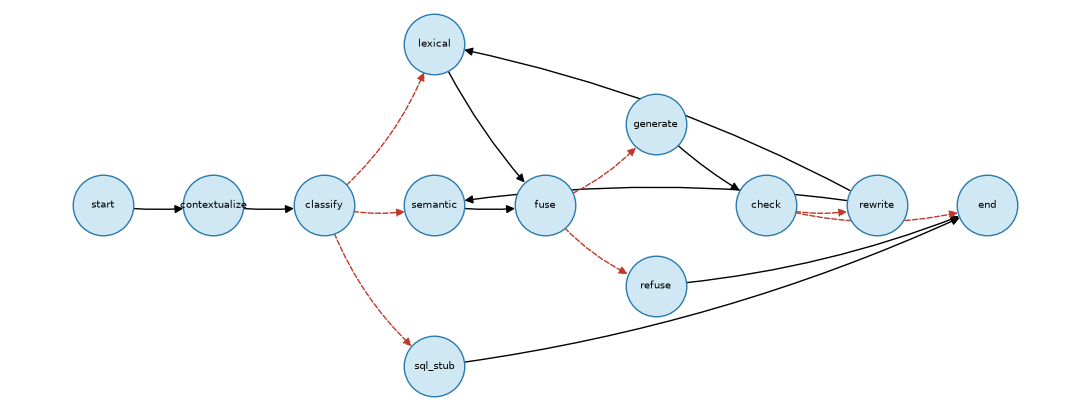

12 nodes, 9 plain edges, 7 conditional edges


In [7]:
import networkx as nx
layer = {"__start__": 0, "contextualize": 1, "classify": 2, "sql_stub": 3, "semantic": 3, "lexical": 3, "fuse": 4,
         "refuse": 5, "generate": 5, "check": 6, "rewrite": 7, "__end__": 8}
G = nx.DiGraph()
for e in graph.edges:
    G.add_edge(e.source, e.target, conditional=e.conditional)
rows = {}
pos = {}
for node in G.nodes:
    rows.setdefault(layer[node], []).append(node)
for x, nodes in rows.items():
    for j, node in enumerate(sorted(nodes)):
        pos[node] = (x, -(j - (len(nodes) - 1) / 2) * 1.2)
fig, ax = plt.subplots(figsize=(11, 4.2))
nx.draw_networkx_nodes(G, pos, node_color="#cfe8f3", node_size=1900, edgecolors="#2a7ab0", ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: n.strip("_") for n in G.nodes}, font_size=7, ax=ax)
solid = [(u, v) for u, v, d in G.edges(data=True) if not d["conditional"]]
dashed = [(u, v) for u, v, d in G.edges(data=True) if d["conditional"]]
nx.draw_networkx_edges(G, pos, edgelist=solid, ax=ax, node_size=1900, arrowsize=12, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edges(G, pos, edgelist=dashed, ax=ax, node_size=1900, arrowsize=12, style="dashed", edge_color="#c0392b", connectionstyle="arc3,rad=0.15")
ax.axis("off"); plt.tight_layout(); plt.show()
print(len(G.nodes), "nodes,", len(solid), "plain edges,", len(dashed), "conditional edges")

## 4. Enrutado: documentos, datos o rechazo

Tres preguntas, tres caminos. La primera va a los dos recuperadores, la segunda es una pregunta sobre cifras que el
manual no puede contener (va al esbozo de SQL), la tercera está fuera de tema y la puerta la rechaza tras la fusión sin
llamar al generador.

In [8]:
for q in ["How soon must an injury be reported?",
          "What was the availability last month?",
          "What is the best pasta recipe?"]:
    out = ask(q)
    print(f"Q: {q}\n   path: {' -> '.join(out['trace'])}\n   A: {out['answer']}\n")

Q: How soon must an injury be reported?
   path: contextualize -> classify -> lexical -> semantic -> fuse -> generate -> check
   A: Any injury or near miss is reported within one hour and a written report is filed within 24 hours. [p19]

Q: What was the availability last month?
   path: contextualize -> classify -> sql_stub
   A: That needs figures from a database; module 06 builds the safe text-to-SQL step.

Q: What is the best pasta recipe?
   path: contextualize -> classify -> lexical -> semantic -> fuse -> refuse
   A: I cannot find that in the handbook.



## 5. Ramas paralelas: qué aportan

Nuestros dos recuperadores tardan milisegundos, así que ejecutarlos en paralelo no gana nada visible. La razón para
hacerlo es el caso *real*: una base de datos vectorial en red, o una llamada a un modelo, que tardan cada una unos
cientos de milisegundos. Pon `LATENCY` para simularlo y compara el grafo (las dos ramas en el mismo paso) con ejecutar
las mismas dos funciones una tras otra.

In [9]:
LATENCY = 0.3
q = "How soon must an injury be reported?"
t0 = time.perf_counter(); ask(q); t_graph = time.perf_counter() - t0

t0 = time.perf_counter()
s = {"question": q, "query": q}
s.update(semantic(s)); s.update(lexical(s)); s.update(fuse(s))
t_seq = time.perf_counter() - t0
LATENCY = 0.0
print(f"two retrievers of {0.3} s each: graph (parallel) {t_graph:.2f} s   sequential {t_seq:.2f} s   ->  {t_seq / t_graph:.1f}x")

two retrievers of 0.3 s each: graph (parallel) 0.34 s   sequential 0.63 s   ->  1.8x


El tiempo del grafo es aproximadamente el de la más lenta de las dos ramas, no su suma. (La latencia se simula con
`sleep`; con llamadas de red reales el efecto es el mismo, y crece con el número de ramas paralelas.) Por eso el agente de
parques eólicos ejecuta la recuperación de documentos y el análisis de imágenes a la vez.

## 6. El bucle de comprobar y reintentar

`check` pregunta si la respuesta está *respaldada*: ¿la frase que vamos a devolver comparte palabras de contenido con la
pregunta? Si no, y quedan reintentos, el grafo pasa a `rewrite` y busca de nuevo con la nueva consulta; cuando se agota
el presupuesto de reintentos **rechaza** en lugar de devolver una respuesta sin respaldo. Míralo con una pregunta
formulada como la haría una persona:

In [10]:
# busca una pregunta que el bucle rescata: rechazada o errónea sin reintento, correcta con un reintento
rescued = next(q for _, q, gold in ANSWERABLE
               if outcome(ask(q, max_retries=0), gold) != "correct" and outcome(ask(q, max_retries=1), gold) == "correct")
for retries in (0, 1):
    out = ask(rescued, max_retries=retries)
    print(f"max_retries={retries}: {' -> '.join(out['trace'])}\n   query used: {out['query']!r}\n   A: {out['answer']}\n")

max_retries=0: contextualize -> classify -> lexical -> semantic -> fuse -> generate -> check
   query used: 'What qualification do I need before getting on the boat?'
   A: I cannot find that in the handbook.

max_retries=1: contextualize -> classify -> lexical -> semantic -> fuse -> generate -> check -> rewrite -> lexical -> semantic -> fuse -> generate -> check
   query used: 'what certificate training do i need before getting on the vessel'
   A: Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. [p01]



La pregunta la eligió el código (la primera de la batería que el bucle convierte de un fallo en una respuesta correcta).
Sin presupuesto de reintentos el sistema falla una pregunta que el manual *sí* puede responder; con un reintento, la
consulta reescrita encuentra el pasaje correcto. Ahora la medición honesta sobre toda la batería: las 24 preguntas con
respuesta y las 4 que no pueden responderse, sin reintento, con un reintento, y sin la puerta de recuperación ni la
comprobación (respondiendo siempre desde el pasaje principal).

In [11]:
def run_battery(max_retries):
    counts = {}
    for _, q, gold in ANSWERABLE + UNANSWERABLE:
        label = outcome(ask(q, max_retries=max_retries), gold)
        counts[label] = counts.get(label, 0) + 1
    return counts

def run_no_guards():
    counts = {}
    for _, q, gold in ANSWERABLE + UNANSWERABLE:
        s = {"question": q, "query": q}
        s.update(semantic(s)); s.update(lexical(s)); s.update(fuse(s)); s.update(generate(s))
        counts[outcome(s, gold)] = counts.get(outcome(s, gold), 0) + 1
    return counts

labels = ["correct", "wrong passage", "refused (answerable)", "correct refusal", "invented answer"]
results = {"no guards (always answer)": run_no_guards(), "gate + check, 0 retries": run_battery(0), "gate + check, 1 retry": run_battery(1)}
print(f"{'':28s}" + "".join(f"{l:>22s}" for l in labels))
for name, c in results.items():
    print(f"{name:28s}" + "".join(f"{c.get(l, 0):22d}" for l in labels))

                                           correct         wrong passage  refused (answerable)       correct refusal       invented answer
no guards (always answer)                       19                     5                     0                     0                     4
gate + check, 0 retries                         17                     4                     3                     4                     0
gate + check, 1 retry                           18                     4                     2                     4                     0


Lee la tabla con tres cautelas. Primero, las protecciones cumplen su función en las preguntas que deben rechazarse: sin
ellas, cada pregunta sin respuesta recibe una respuesta inventada. Segundo, las protecciones no son gratis: las
preguntas con respuesta que ya salían bien sin ellas no salen todas bien con ellas (la comprobación rechaza algunas
respuestas correctas cuya redacción no comparte ninguna palabra con la pregunta), así que la columna "correct" *baja* de
19 a 17 antes de que el reintento la devuelva a 18. Cambias unos pocos rechazos indebidos por ninguna respuesta inventada;
para un manual de seguridad suele ser el trato correcto, pero es un trato, y la tabla es cómo lo ves. Tercero, el
reescritor del reintento de arriba es una **tabla de sinónimos escrita a mano después de mirar estas mismas preguntas**,
así que la mejora que muestra aquí es una *cota superior* que demuestra el mecanismo, no una estimación de lo que logra
un reescritor real con preguntas nuevas. El módulo 07 muestra cómo medirlo bien con preguntas apartadas del ajuste.
Fíjate también en lo que ninguna protección puede hacer: cuando el pasaje principal es el equivocado pero comparte una
palabra con la pregunta, la comprobación pasa y se devuelve un pasaje erróneo. Las comprobaciones baratas detectan los
fallos gruesos; los sutiles necesitan un juez.

## 7. Puntos de control: memoria por conversación

Un grafo compilado con un **checkpointer** guarda su estado tras cada paso bajo un `thread_id`. Si lo invocas de nuevo
con el mismo hilo, el estado guardado vuelve, de modo que la lista `history` sigue creciendo y el nodo `contextualize`
puede resolver un seguimiento. Un hilo distinto empieza de cero. `MemorySaver` lo guarda en RAM; LangGraph también tiene
checkpointers de SQLite y Postgres para conversaciones duraderas y para pausar un grafo a la espera de una persona.

In [12]:
chat = build_graph(checkpointer=MemorySaver())
alice = {"configurable": {"thread_id": "alice"}}
bob = {"configurable": {"thread_id": "bob"}}

follow_up = "And who decides that?"
r1 = ask("What wave height stops the crew boats from sailing?", graph=chat, config=alice)
print("alice 1:", r1["answer"])
r2 = ask(follow_up, graph=chat, config=alice)
print("alice 2:", follow_up, "->", r2["answer"], "\n         query used:", repr(r2["query"]))
r3 = ask(follow_up, graph=chat, config=bob)
print("bob   1:", follow_up, "->", r3["answer"])
print("\nsaved history of thread alice:", chat.get_state(alice).values["history"])
print("saved history of thread bob  :", chat.get_state(bob).values["history"])

alice 1: Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [p02]
alice 2: And who decides that? -> The duty coordinator decides at 06:00 and may cancel later. [p02] 
         query used: 'And who decides that? (previous question: What wave height stops the crew boats from sailing?)'
bob   1: And who decides that? -> I cannot find that in the handbook.

saved history of thread alice: ['What wave height stops the crew boats from sailing?', 'And who decides that?']
saved history of thread bob  : ['And who decides that?']


El seguimiento de Alice funciona porque el hilo recuerda su primera pregunta; las mismas palabras de Bob, que no tiene
historial, se buscan tal cual y no encuentran nada relevante. El estado por conversación también es una **frontera de
privacidad**: nunca dejes que dos usuarios compartan un `thread_id`.

## 8. Cuándo compensa un grafo

Un grafo se gana su sitio cuando el flujo tiene **ramas, bucles, trabajo en paralelo o estado que debe sobrevivir**: la
decisión doble recomendar/reentrenar del agente de parques eólicos y sus pasos paralelos de recuperación y visión son
justo eso. Para un servicio recto de recuperar y generar, una función normal es más simple y igual de comprobable, y el
pipeline de los módulos anteriores no necesita ningún framework. Dos ventajas prácticas son independientes de lo
complejo que sea tu flujo: el **trace** (puedes afirmar en una prueba que una pregunta siguió el camino esperado) y el
**estado explícito** (cada valor intermedio se puede inspeccionar, que es sobre lo que se apoya el módulo de
observabilidad de este curso).

## Ejercicios

1. Añade a `DATA_WORDS` preguntas de tipo `"data"` propias y confirma con `trace` que se saltan los dos recuperadores.
2. Pon `max_retries=3`. ¿Cambia la tabla medida? ¿Por qué una segunda reescritura del mismo texto no aporta nada, y qué
   tendría que hacer distinto un reescritor en el segundo intento?
3. Añade un nodo `log_unanswered` entre `refuse` y `END` que añada la pregunta a una lista. Es la semilla del bucle de
   mejora del módulo 08: ¿qué harías con esa lista?
4. Quita `contextualize` del grafo y repite el seguimiento de Alice. ¿Qué sigue guardando el checkpointer, y por qué el
   seguimiento falla ahora aunque el historial esté ahí?